# Step 1: Data ingestion and chunking
The Big Five banks file their annual report (MD&A and audited statements) and Annual Information Form with the SEC on Form 40-F. We download the fiscal 2024 and 2025 filings from SEC EDGAR (`jarvis.download`), then parse them (`jarvis.ingest`): page numbers from the filings' own page breaks, headings from layout signals, tables kept whole, boilerplate removed, chunks of 500 to 1,000 tokens with about 150 tokens of overlap inside a section.

In [1]:
import sys, json, pandas as pd
sys.path.insert(0, '../src')
pd.set_option('display.max_colwidth', 120)

In [2]:
index = pd.read_csv('../data/processed/filing_index.csv')
index

,filing_id,bank,document_type,fiscal_year,filed,pages,chunks,tokens,source_url
0,RBC_2024_AIF,RBC,Annual Information Form,2024,2024-12-04,93,54,29203,https://www.sec.gov/Archives/edgar/data/1000275/000119312524270294/d848219dex1.htm
1,RBC_2024_AR,RBC,Annual Report,2024,2024-12-04,450,397,217825,https://www.sec.gov/Archives/edgar/data/1000275/000119312524270294/d848219dex2.htm
2,RBC_2025_AIF,RBC,Annual Information Form,2025,2025-12-03,91,53,28438,https://www.sec.gov/Archives/edgar/data/1000275/000119312525305927/d95203dex1.htm
3,RBC_2025_AR,RBC,Annual Report,2025,2025-12-03,444,380,204210,https://www.sec.gov/Archives/edgar/data/1000275/000119312525305927/d95203dex2.htm
4,TD_2024_AIF,TD,Annual Information Form,2024,2024-12-06,47,50,28691,https://www.sec.gov/Archives/edgar/data/947263/000156276224000281/ex991.htm
5,TD_2024_MDA,TD,Annual Report (MD&A),2024,2024-12-06,120,251,142176,https://www.sec.gov/Archives/edgar/data/947263/000156276224000281/ex992.htm
6,TD_2024_FS,TD,Financial Statements,2024,2024-12-06,98,161,101453,https://www.sec.gov/Archives/edgar/data/947263/000156276224000281/ex993.htm
7,TD_2025_AIF,TD,Annual Information Form,2025,2025-12-04,45,51,27789,https://www.sec.gov/Archives/edgar/data/947263/000156276225000289/ex991.htm
8,TD_2025_MDA,TD,Annual Report (MD&A),2025,2025-12-04,116,246,135663,https://www.sec.gov/Archives/edgar/data/947263/000156276225000289/ex992.htm
9,TD_2025_FS,TD,Financial Statements,2025,2025-12-04,98,154,97312,https://www.sec.gov/Archives/edgar/data/947263/000156276225000289/ex993.htm


In [3]:
chunks = pd.read_json('../data/processed/chunks.jsonl', lines=True)
print(len(chunks), 'chunks,', chunks.tokens.sum(), 'tokens')
chunks.groupby(['bank', 'document_type']).agg(chunks=('chunk_id', 'count'), tokens=('tokens', 'sum'))

4301 chunks, 2315258 tokens


chunks  tokens
bank document_type                          
BMO  Annual Information Form      96   53905
     Annual Report (MD&A)        400  200879
     Financial Statements        278  148088
BNS  Annual Information Form      99   59002
     Annual Report (MD&A)        477  252802
     Financial Statements        369  188530
CIBC Annual Information Form      67   34793
     Annual Report (MD&A)        378  188781
     Financial Statements        340  175718
RBC  Annual Information Form     107   57641
     Annual Report               777  422035
TD   Annual Information Form     101   56480
     Annual Report (MD&A)        497  277839
     Financial Statements        315  198765

## Token analysis and estimated embedding cost
Titan Text Embeddings v2 costs about $0.02 per million tokens; the local models are free.

In [4]:
tok = chunks.tokens.sum()
print(f'{tok:,} tokens -> Titan v2 about ${tok / 1e6 * 0.02:.2f}; OpenAI text-embedding-3-small about ${tok / 1e6 * 0.02:.2f}')

2,315,258 tokens -> Titan v2 about $0.05; OpenAI text-embedding-3-small about $0.05


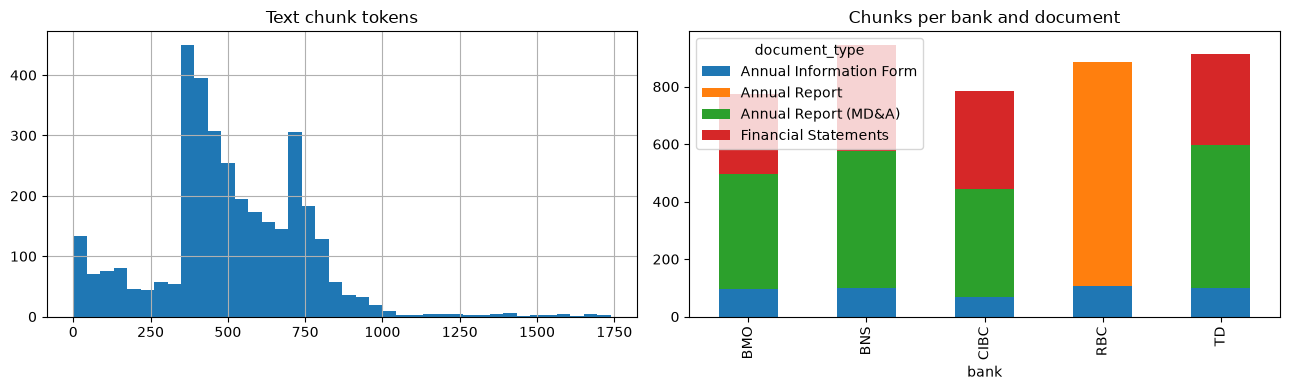

In [5]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
chunks[chunks.chunk_type == 'text'].tokens.hist(bins=40, ax=ax[0]); ax[0].set_title('Text chunk tokens')
chunks.groupby(['bank', 'document_type']).size().unstack().plot.bar(stacked=True, ax=ax[1])
ax[1].set_title('Chunks per bank and document'); plt.tight_layout()

In [6]:
chunks[['chunk_id', 'section', 'risk_category', 'page', 'tokens']].sample(8, random_state=1)

,chunk_id,section,risk_category,page,tokens
407,RBC_2024_AR#0353,Market risk,market,408,34
90,RBC_2024_AR#0036,Business segment results,regulatory,41,249
1396,TD_2025_AIF#0050,Of The Board Of Directors,regulatory,44,470
4178,CIBC_2025_MDA#0057,"Regulatory capital, leverage and TLAC ratios",regulatory,73,53
1453,TD_2025_MDA#0056,Business Segment Analysis,market,30,366
2801,BNS_2024_MDA#0180,Liquidity Risk,regulatory,181,615
4043,CIBC_2025_FS#0093,Accounting for financial instruments,general,89,169
123,RBC_2024_AR#0069,Financial condition,liquidity,85,665


Two filings needed special handling: TD's exhibits are PDF pages converted to positioned HTML boxes (a layout reader rebuilds columns, lines and paragraphs), and CIBC and BMO number their MD&A and statements the other way round (the document type is read from the content, not the exhibit number).

## Quarterly Reports to Shareholders (PDF)
The brief also asks for the quarterly reports. `jarvis.download_quarterly` fetches the Q1 to Q3 reports for fiscal 2024 and 2025 from each bank's investor relations site (30 PDFs; Q4 is covered by the annual report), with a manifest of URL, size and sha256. `jarvis.ingest_pdf` reads them with PyMuPDF and feeds the same cleaning and chunking: running headers and footers are dropped by position, headings come from font size and weight, and tables (which have no ruling lines in these reports) are rebuilt from positions: lines at the same height with two or more figures form a row, and neighbouring rows, column headers and wrapped labels form one table.

In [7]:
qman = pd.read_json('../data/raw/quarterly/manifest.json')
qman[['bank', 'fiscal_year', 'quarter', 'size', 'url']].head(6)

,bank,fiscal_year,quarter,size,url
0,RBC,2024,Q1,866422,https://www.rbc.com/investor-relations/_assets-custom/pdf/2024q1_report.pdf
1,RBC,2024,Q2,915925,https://www.rbc.com/investor-relations/_assets-custom/pdf/2024q2_report.pdf
2,RBC,2024,Q3,900565,https://www.rbc.com/investor-relations/_assets-custom/pdf/2024q3_report.pdf
3,RBC,2025,Q1,961887,https://www.rbc.com/investor-relations/_assets-custom/pdf/2025q1_report.pdf
4,RBC,2025,Q2,932918,https://www.rbc.com/investor-relations/_assets-custom/pdf/2025q2_report.pdf
5,RBC,2025,Q3,1024482,https://www.rbc.com/investor-relations/_assets-custom/pdf/2025q3_report.pdf


In [8]:
qindex = pd.read_csv('../data/processed/filing_index_quarterly.csv')
qindex.pivot_table(index='bank', columns=['fiscal_year', 'quarter'], values='chunks')

fiscal_year   2024                 2025              
quarter         Q1     Q2     Q3     Q1     Q2     Q3
bank                                                 
BMO          160.0  183.0  185.0  151.0  177.0  182.0
BNS          186.0  219.0  237.0  189.0  221.0  224.0
CIBC         171.0  204.0  206.0  166.0  196.0  197.0
RBC          157.0  184.0  187.0  144.0  172.0  175.0
TD           179.0  213.0  220.0  164.0  202.0  215.0

In [9]:
qchunks = pd.read_json('../data/processed/chunks_quarterly.jsonl', lines=True)
print(len(qchunks), 'quarterly chunks,', qchunks.tokens.sum(), 'tokens;', len(chunks) + len(qchunks), 'chunks in all')
qchunks.chunk_type.value_counts()

5666 quarterly chunks, 3043296 tokens; 9967 chunks in all


chunk_type
text     3634
table    2032
Name: count, dtype: int64

A table rebuilt from a PDF page (BMO, Q2 2025, page 6): the column headings stay with their figures.

In [10]:
t = qchunks[(qchunks.filing_id == 'BMO_2025_Q2') & (qchunks.text.str.contains('Q2-2025'))].iloc[0]
print(t.section, '| page', t.page)
print(t.text[:900])

Financial Highlights | page 6
[Financial Highlights]
TABLE 1
(Canadian$inmillions, exceptas noted) | Q2-2025 | Q1-2025 | Q2-2024 | YTD-2025 | YTD-2024
Summary Income Statement Note 1, Page 6
Net interest income | 5,097 | 5,398 | 4,515 | 10,495 | 9,236
Non-interest revenue | 3,582 | 3,868 | 3,459 | 7,450 | 6,410
Revenue | 8,679 | 9,266 | 7,974 | 17,945 | 15,646
Provision for credit losses on impaired loans | 765 | 859 | 658 | 1,624 | 1,131
Provision for credit losses on performing loans | 289 | 152 | 47 | 441 | 201
Total provision for credit losses (PCL) | 1,054 | 1,011 | 705 | 2,065 | 1,332
Non-interest expense | 5,019 | 5,427 | 4,844 | 10,446 | 10,233
Provision for income taxes | 644 | 690 | 559 | 1,334 | 923
Net income | 1,962 | 2,138 | 1,866 | 4,100 | 3,158
Net income attributable to non-controlling interest in subsidiaries | 2 | 4 | 4 | 6 | 6
Dividends on preferred shares and distributions on other equity instrum
